# Atelier 2 — Profiler les données e-commerce avec Pandas
## Projet fil rouge : BigData Commerce Analytics

**Niveau :** B2 · **Modalité :** individuel ou binôme · 

### Mission
Vous êtes Data Analysts. Vous recevez une table de lignes de panier issue de DummyJSON. Vous devez en comprendre la granularité, vérifier sa structure, mesurer sa qualité et proposer un plan de nettoyage avant stockage dans MongoDB et traitement avec Spark.

### Objectifs pédagogiques
- Charger un CSV et contrôler sa structure.
- Distinguer ligne, panier, utilisateur et produit.
- Mesurer valeurs manquantes, doublons et incohérences.
- Détecter valeurs atypiques et erreurs de typage.
- Documenter les transformations sans détruire les données brutes.

> **Avertissement métier :** le fichier représente des lignes de paniers de démonstration. Ce n'est pas un historique réel de commandes. La colonne `order_date` est synthétique si le fichier a été généré par le script de collecte. Ne l'utilisez pas pour conclure sur une saisonnalité réelle.


## 0. Préparation et chargement
Le fichier complet est créé par `scripts/01_collecte_dummyjson.py` dans `data/processed/commandes_ecommerce.csv`. Si la collecte n'a pas été exécutée, ce notebook utilise le petit échantillon hors ligne de `data/raw/commandes_ecommerce.csv`.


In [16]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
processed = ROOT / "data" / "processed" / "commandes_ecommerce.csv"
sample = ROOT / "data" / "raw" / "commandes_ecommerce.csv"
DATA_FILE = processed if processed.exists() else sample
print("Fichier chargé :", DATA_FILE)
df_brut = pd.read_csv(DATA_FILE)
df = df_brut.copy()
display(df.head())


Fichier chargé : c:\Users\Timéo\Documents\Sup 2 vinci\B2\Big Data\BigData_Commerce_Analytics_DummyJSON\data\raw\commandes_ecommerce.csv


,order_id,cart_id,user_id,product_id,product_title,category,quantity,unit_price,line_total,discount_percentage,discounted_line_total,cart_total,order_date
0,DEMO-0001,1,1,1,Essence Mascara Lash Princess,beauty,2,9.99,19.98,7.17,18.55,39.97,2025-01-01
1,DEMO-0001,1,1,2,Eyeshadow Palette,beauty,1,19.99,19.99,5.00,18.99,39.97,2025-01-01
2,DEMO-0002,2,2,3,Powder Canister,groceries,3,14.99,44.97,10.00,40.47,44.97,2025-01-01


## 1. Comprendre la granularité

La granularité décrit ce que représente **une ligne**. Ici, une ligne correspond à un produit dans un panier (ligne de panier), et non nécessairement à une commande métier finalisée.

Questions :
1. Une même valeur `order_id` peut-elle apparaître plusieurs fois ? Pourquoi ?
2. Quelle différence entre `cart_id` et `product_id` ?
3. Pourquoi ne faut-il pas additionner `cart_total` sur chaque ligne sans précaution ?


In [2]:
print("Dimensions (lignes, colonnes) :", df.shape)
print("Nombre de paniers :", df["cart_id"].nunique() if "cart_id" in df else "colonne absente")
print("Nombre de produits :", df["product_id"].nunique() if "product_id" in df else "colonne absente")
print("Nombre d'utilisateurs :", df["user_id"].nunique() if "user_id" in df else "colonne absente")
print("Nombre de lignes :", len(df))


Dimensions (lignes, colonnes) : (3, 13)
Nombre de paniers : 2
Nombre de produits : 3
Nombre d'utilisateurs : 2
Nombre de lignes : 3


## 2. Types et structure des colonnes

Un identifiant est souvent un entier ou une chaîne, un prix un nombre décimal et une date un objet datetime. Vérifiez les types avant de calculer.


In [3]:
df.info()
display(df.dtypes.astype(str).to_frame("type détecté"))


<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               3 non-null      str    
 1   cart_id                3 non-null      int64  
 2   user_id                3 non-null      int64  
 3   product_id             3 non-null      int64  
 4   product_title          3 non-null      str    
 5   category               3 non-null      str    
 6   quantity               3 non-null      int64  
 7   unit_price             3 non-null      float64
 8   line_total             3 non-null      float64
 9   discount_percentage    3 non-null      float64
 10  discounted_line_total  3 non-null      float64
 11  cart_total             3 non-null      float64
 12  order_date             3 non-null      str    
dtypes: float64(5), int64(4), str(4)
memory usage: 444.0 bytes


,type détecté
order_id,str
cart_id,int64
user_id,int64
product_id,int64
product_title,str
category,str
quantity,int64
unit_price,float64
line_total,float64
discount_percentage,float64


In [4]:
# Conversion explicite des champs numériques et de la date
numeric_cols = ["quantity", "unit_price", "line_total", "discount_percentage",
                "discounted_line_total", "cart_total", "cart_discounted_total"]
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

if "order_date" in df.columns:
    df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")

display(df.dtypes.astype(str).to_frame("type après conversion"))


,type après conversion
order_id,str
cart_id,int64
user_id,int64
product_id,int64
product_title,str
category,str
quantity,int64
unit_price,float64
line_total,float64
discount_percentage,float64


## 3. Valeurs manquantes et doublons

Une valeur manquante n'est pas toujours une erreur : il faut comprendre le sens du champ. Un doublon exact n'est pas la même chose que deux lignes portant le même `order_id` (ce qui est normal si un panier contient plusieurs produits).


In [5]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (df.isna().mean() * 100).round(2)
qualite_manquants = pd.DataFrame({"valeurs_manquantes":missing, "pourcentage":missing_pct})
display(qualite_manquants)
print("Doublons exacts :", df.duplicated().sum())


,valeurs_manquantes,pourcentage
order_id,0,0.0
cart_id,0,0.0
user_id,0,0.0
product_id,0,0.0
product_title,0,0.0
category,0,0.0
quantity,0,0.0
unit_price,0,0.0
line_total,0,0.0
discount_percentage,0,0.0


Doublons exacts : 0


In [6]:
# Doublons sur une clé métier candidate : panier + produit
key_cols = [c for c in ["cart_id", "product_id"] if c in df.columns]
if len(key_cols) == 2:
    print("Doublons sur cart_id + product_id :", df.duplicated(subset=key_cols).sum())


Doublons sur cart_id + product_id : 0


## 4. Statistiques descriptives et valeurs atypiques

Examinez les distributions. Les valeurs extrêmes ne sont pas automatiquement des erreurs : un article cher peut être légitime. Il faut vérifier le contexte et la source.


In [7]:
display(df.describe(include="all").T)


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
order_id,3,2,DEMO-0001,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cart_id,3.0,NaN,NaN,NaN,1.333333,1.0,1.0,1.0,1.5,2.0,0.57735
user_id,3.0,NaN,NaN,NaN,1.333333,1.0,1.0,1.0,1.5,2.0,0.57735
product_id,3.0,NaN,NaN,NaN,2.0,1.0,1.5,2.0,2.5,3.0,1.0
product_title,3,3,Essence Mascara Lash Princess,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,3,2,beauty,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,3.0,NaN,NaN,NaN,2.0,1.0,1.5,2.0,2.5,3.0,1.0
unit_price,3.0,NaN,NaN,NaN,14.99,9.99,12.49,14.99,17.49,19.99,5.0
line_total,3.0,NaN,NaN,NaN,28.313333,19.98,19.985,19.99,32.48,44.97,14.425097
discount_percentage,3.0,NaN,NaN,NaN,7.39,5.0,6.085,7.17,8.585,10.0,2.507249


In [8]:
for col in [c for c in ["quantity","unit_price","line_total","discount_percentage","discounted_line_total"] if c in df.columns]:
    print(f"\n{col}")
    print(df[col].describe())



quantity
count    3.0
mean     2.0
std      1.0
min      1.0
25%      1.5
50%      2.0
75%      2.5
max      3.0
Name: quantity, dtype: float64

unit_price
count     3.00
mean     14.99
std       5.00
min       9.99
25%      12.49
50%      14.99
75%      17.49
max      19.99
Name: unit_price, dtype: float64

line_total
count     3.000000
mean     28.313333
std      14.425097
min      19.980000
25%      19.985000
50%      19.990000
75%      32.480000
max      44.970000
Name: line_total, dtype: float64

discount_percentage
count     3.000000
mean      7.390000
std       2.507249
min       5.000000
25%       6.085000
50%       7.170000
75%       8.585000
max      10.000000
Name: discount_percentage, dtype: float64

discounted_line_total
count     3.000000
mean     26.003333
std      12.530432
min      18.550000
25%      18.770000
50%      18.990000
75%      29.730000
max      40.470000
Name: discounted_line_total, dtype: float64


## 5. Contrôles de cohérence métier

Vérifiez les règles suivantes :
- quantité strictement positive ;
- prix unitaire positif ou nul selon la règle métier à définir ;
- pourcentage de remise compris entre 0 et 100 ;
- total de ligne proche de quantité × prix unitaire ;
- total remisé inférieur ou égal au total initial ;
- identifiants de produits et paniers renseignés.

Un écart d'arrondi de quelques centimes peut être normal.


In [9]:
checks = {}
if "quantity" in df:
    checks["quantite_non_positive"] = int((df["quantity"] <= 0).sum())
if "unit_price" in df:
    checks["prix_negatif"] = int((df["unit_price"] < 0).sum())
if "discount_percentage" in df:
    checks["remise_hors_0_100"] = int(((df["discount_percentage"] < 0) | (df["discount_percentage"] > 100)).sum())
if {"quantity","unit_price","line_total"}.issubset(df.columns):
    expected = df["quantity"] * df["unit_price"]
    checks["ecart_total_ligne_superieur_1_centime"] = int(((df["line_total"] - expected).abs() > 0.01).sum())
if {"line_total","discounted_line_total"}.issubset(df.columns):
    checks["total_remise_superieur_total_initial"] = int((df["discounted_line_total"] > df["line_total"] + 0.01).sum())
display(pd.DataFrame(list(checks.items()), columns=["controle","nombre_anomalies"]))


,controle,nombre_anomalies
0,quantite_non_positive,0
1,prix_negatif,0
2,remise_hors_0_100,0
3,ecart_total_ligne_superieur_1_centime,0
4,total_remise_superieur_total_initial,0


## 6. Analyse exploratoire simple

Les graphiques ci-dessous décrivent les données présentes dans l'instantané. Ils ne doivent pas être interprétés comme des tendances réelles du marché.


,total_lignes_panier
category,
groceries,44.97
beauty,39.97


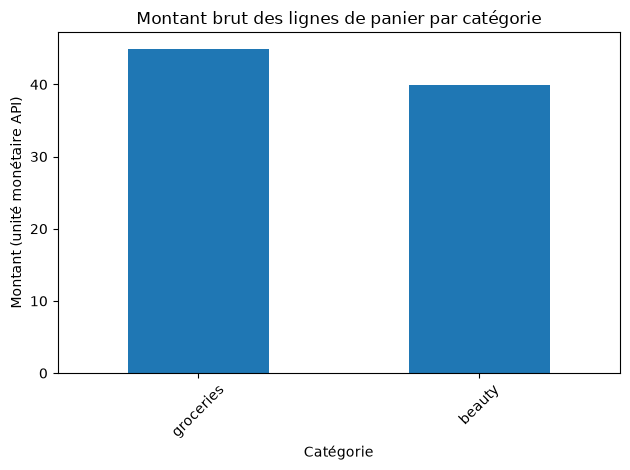

In [10]:
if "category" in df and "line_total" in df:
    ca_categorie = df.groupby("category", dropna=False)["line_total"].sum().sort_values(ascending=False)
    display(ca_categorie.to_frame("total_lignes_panier"))
    ca_categorie.plot(kind="bar", title="Montant brut des lignes de panier par catégorie", ylabel="Montant (unité monétaire API)", xlabel="Catégorie", rot=45)
    plt.tight_layout()
    plt.show()


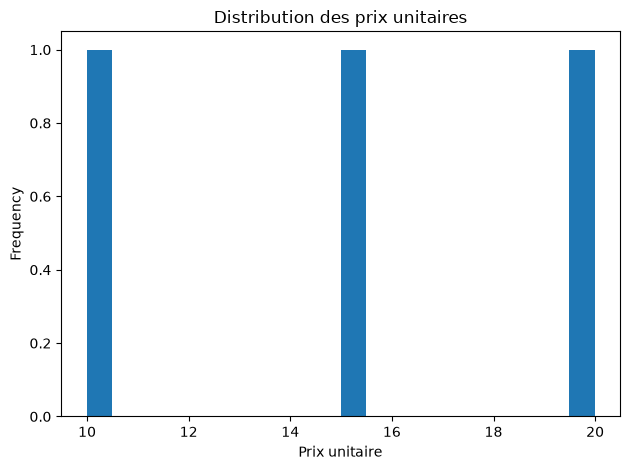

In [11]:
if "unit_price" in df:
    df["unit_price"].dropna().plot(kind="hist", bins=20, title="Distribution des prix unitaires", xlabel="Prix unitaire")
    plt.tight_layout()
    plt.show()


## 7. Construire un jeu nettoyé — sans écraser la source

Conservez `df_brut`. Créez une copie et appliquez des règles explicites. Ne remplacez pas toutes les valeurs manquantes par la chaîne `inconnu` : cela peut transformer des colonnes numériques en texte.


In [12]:
df_clean = df.copy()

# Règles de nettoyage pédagogiques : à adapter après observation des anomalies.
if "quantity" in df_clean:
    df_clean = df_clean[df_clean["quantity"].notna() & (df_clean["quantity"] > 0)]
if "unit_price" in df_clean:
    df_clean = df_clean[df_clean["unit_price"].notna() & (df_clean["unit_price"] >= 0)]
if "cart_id" in df_clean and "product_id" in df_clean:
    df_clean = df_clean.drop_duplicates(subset=["cart_id", "product_id"], keep="first")

print("Avant :", df.shape)
print("Après :", df_clean.shape)


Avant : (3, 13)
Après : (3, 13)


In [13]:
# Sauvegarder dans data/processed/ (ne pas écraser le CSV brut)
OUT = ROOT / "data" / "processed"
OUT.mkdir(parents=True, exist_ok=True)
clean_path = OUT / "commandes_ecommerce_nettoyees.csv"
df_clean.to_csv(clean_path, index=False)
print("Fichier nettoyé enregistré :", clean_path)


Fichier nettoyé enregistré : c:\Users\Timéo\Documents\Sup 2 vinci\B2\Big Data\BigData_Commerce_Analytics_DummyJSON\data\processed\commandes_ecommerce_nettoyees.csv


## 8. Conclusion et livrable

Rédigez une courte note de qualité contenant :
1. le nombre de lignes et de colonnes ;
2. la granularité du fichier ;
3. les types à corriger ;
4. le nombre de valeurs manquantes et de doublons ;
5. trois anomalies ou limites observées ;
6. les règles de nettoyage retenues ;
7. les précautions à prendre avant chargement dans MongoDB ou Spark.

### Questions de réflexion
- Pourquoi faut-il garder une copie brute ?
- Pourquoi `cart_total` ne doit-il pas être additionné ligne par ligne ?
- Quelle différence entre qualité technique et pertinence métier ?
- Quelles limites viennent de la source DummyJSON plutôt que de votre code ?

**Livrable :** le notebook exécuté, `commandes_ecommerce_nettoyees.csv` et une note de qualité d'une page.
